## Results 2026-10-15 - frontier figures

Frontier figures for `docs/results/2026-10-15-results.md`. The values are copied by hand from that document (sections 1, 1.1 and 2), not read from the result artifacts. Frontier membership is recomputed from the document's rule: a variant is off the frontier when another variant is at least as small (or fast) and has a strictly lower quality loss.

setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def find_project_root(start):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'src' / 'mlp_replacement').is_dir():
            return candidate
    raise RuntimeError('Could not locate the repository root')


PROJECT_ROOT = find_project_root(Path.cwd())
RESULTS_DOCUMENT_PATH = PROJECT_ROOT / 'docs' / 'results' / '2026-10-15-results.md'
FIGURE_DIRECTORY = PROJECT_ROOT / 'docs' / 'images' / 'results' / '2026-10-15'
SAVE_FIGURES = True
FIGURE_DPI = 150

FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)

values from the results document

In [3]:
# 8K KL, test PPL and TTFT are None where the document has no measurement.
records = [
    ('Dense', 'dense', 0.0, 0.0000, 6.93, 80.2),
    ('SwiGLU 20%', 'swiglu', 12.9, 0.0787, 7.73, 79.0),
    ('SwiGLU 30%', 'swiglu', 19.4, 0.1161, 8.17, 73.6),
    ('SwiGLU 40%', 'swiglu', 25.9, 0.1701, 8.84, 70.7),
    ('INT8 PTQ', 'quant', 32.3, 0.0030, 6.94, 90.5),
    ('SwiGLU 50%', 'swiglu', 32.4, 0.2288, 9.64, 67.1),
    ('SwiGLU 60%', 'swiglu', 38.8, 0.3040, 10.84, 69.5),
    ('SwiGLU 70%', 'swiglu', 45.3, 0.4094, 12.47, 65.0),
    ('INT4 PTQ', 'quant', 47.5, 0.0896, 7.42, 82.8),
    ('INT4 QAT 100M', 'quant', 47.5, 0.0360, 7.21, None),
    ('INT4 QAT 1B', 'quant', 47.5, 0.0352, 7.24, 82.7),
    ('SwiGLU 75%', 'swiglu', 48.5, 0.4707, 13.65, 60.8),
    ('SwiGLU 80%', 'swiglu', 51.8, 0.5433, 14.97, 60.2),
    ('SwiGLU 20% 1B', 'swiglu_1b', 12.9, None, 7.56, None),
    ('SwiGLU 30% 1B', 'swiglu_1b', 19.4, None, 7.87, None),
    ('SwiGLU 40% 1B', 'swiglu_1b', 25.9, None, 8.31, None),
    ('SwiGLU 50% 1B', 'swiglu_1b', 32.4, None, 8.86, None),
]
variants = pd.DataFrame(
    records,
    columns=['variant', 'group', 'byte_saving', 'kl_8k', 'test_ppl_8k', 'ttft_ms'],
)
variants

,variant,group,byte_saving,kl_8k,test_ppl_8k,ttft_ms
0,Dense,dense,0.0,0.0000,6.93,80.2
1,SwiGLU 20%,swiglu,12.9,0.0787,7.73,79.0
2,SwiGLU 30%,swiglu,19.4,0.1161,8.17,73.6
3,SwiGLU 40%,swiglu,25.9,0.1701,8.84,70.7
4,INT8 PTQ,quant,32.3,0.0030,6.94,90.5
5,SwiGLU 50%,swiglu,32.4,0.2288,9.64,67.1
6,SwiGLU 60%,swiglu,38.8,0.3040,10.84,69.5
7,SwiGLU 70%,swiglu,45.3,0.4094,12.47,65.0
8,INT4 PTQ,quant,47.5,0.0896,7.42,82.8
9,INT4 QAT 100M,quant,47.5,0.0360,7.21,NaN


plot style

In [4]:
SURFACE = '#fcfcfb'
TEXT = '#0b0b0b'
TEXT_SECONDARY = '#52514e'
GRID = '#e4e3df'
FRONTIER = '#8a8984'
DOMINATED_FILL = '#efeeeb'

GROUP_STYLES = {
    'dense': {'color': '#52514e', 'marker': '*', 'size': 170, 'label': 'Dense BF16'},
    'quant': {'color': '#eb6834', 'marker': 's', 'size': 64, 'label': 'Quantization'},
    'swiglu': {'color': '#2a78d6', 'marker': 'o', 'size': 64, 'label': 'SwiGLU, 100M recovery'},
    'swiglu_1b': {'color': '#1baf7a', 'marker': 'D', 'size': 58, 'label': 'SwiGLU, 1B recovery'},
}

frontier

In [5]:
def frontier(points, x_better_high):
    on_frontier = []
    for point in points.itertuples(index=False):
        dominated = any(
            other.variant != point.variant
            and (other.x >= point.x if x_better_high else other.x <= point.x)
            and other.y < point.y
            for other in points.itertuples(index=False)
        )
        if not dominated:
            on_frontier.append(point)
    return sorted(on_frontier, key=lambda point: point.x, reverse=not x_better_high)


def plot_frontier(x_column, y_column, x_better_high, title, xlabel, ylabel, note, labels, xlim, ylim, filename):
    points = (
        variants.dropna(subset=[x_column, y_column])
        .rename(columns={x_column: 'x', y_column: 'y'})
        [['variant', 'group', 'x', 'y']]
    )
    on_frontier = frontier(points, x_better_high)
    print(filename, 'frontier:', [point.variant for point in on_frontier])

    fig, ax = plt.subplots(figsize=(8.4, 5.4), dpi=FIGURE_DPI)
    fig.patch.set_facecolor(SURFACE)
    ax.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TEXT_SECONDARY, labelsize=9)
    ax.set_title(title, loc='left', color=TEXT, fontsize=12, pad=12)
    ax.set_xlabel(xlabel, color=TEXT_SECONDARY, fontsize=10)
    ax.set_ylabel(ylabel, color=TEXT_SECONDARY, fontsize=10)

    # Staircase: the best y reachable while keeping x at least as good.
    staircase_x, staircase_y = [], []
    for index, point in enumerate(on_frontier):
        if index:
            staircase_x.append(on_frontier[index - 1].x)
            staircase_y.append(point.y)
        staircase_x.append(point.x)
        staircase_y.append(point.y)
    # Nothing is dominated beyond the best-x frontier point, so the fill stops there.
    worst_x_edge = xlim[0] if x_better_high else xlim[1]
    ax.fill_between(
        [worst_x_edge] + staircase_x,
        [staircase_y[0]] + staircase_y,
        ylim[1],
        color=DOMINATED_FILL,
        zorder=0,
    )
    ax.plot(staircase_x, staircase_y, color=FRONTIER, linewidth=1.6, zorder=1, label='Frontier')
    better_x = 'smaller-or-equal' if x_better_high else 'faster-or-equal'
    ax.text(
        0.02 if x_better_high else 0.98,
        0.96,
        f'dominated region: something else is {better_x} and better',
        transform=ax.transAxes,
        ha='left' if x_better_high else 'right',
        va='top',
        fontsize=8,
        color=TEXT_SECONDARY,
    )

    for group, style in GROUP_STYLES.items():
        group_points = points[points['group'] == group]
        if group_points.empty:
            continue
        ax.scatter(
            group_points['x'],
            group_points['y'],
            s=style['size'],
            marker=style['marker'],
            color=style['color'],
            edgecolor=SURFACE,
            linewidth=1.5,
            zorder=3,
            label=style['label'],
        )

    frontier_variants = {point.variant for point in on_frontier}
    for point in points.itertuples(index=False):
        if point.variant not in labels:
            continue
        offset_x, offset_y = labels[point.variant]
        ax.annotate(
            point.variant,
            (point.x, point.y),
            xytext=(offset_x, offset_y),
            textcoords='offset points',
            fontsize=8,
            color=TEXT,
            fontweight='bold' if point.variant in frontier_variants else 'normal',
            ha='left' if offset_x >= 0 else 'right',
            va='center',
        )

    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, -0.13),
        ncol=5,
        frameon=False,
        fontsize=8.5,
        labelcolor=TEXT_SECONDARY,
        handletextpad=0.4,
        columnspacing=1.2,
    )
    fig.text(0.01, 0.01, note, fontsize=7.5, color=TEXT_SECONDARY)
    fig.tight_layout(rect=(0, 0.03, 1, 1))
    if SAVE_FIGURES:
        fig.savefig(FIGURE_DIRECTORY / filename, facecolor=SURFACE)
    plt.show()

size frontier, 8K KL

frontier-size-kl.png frontier: ['Dense', 'INT8 PTQ', 'INT4 QAT 1B', 'SwiGLU 75%', 'SwiGLU 80%']


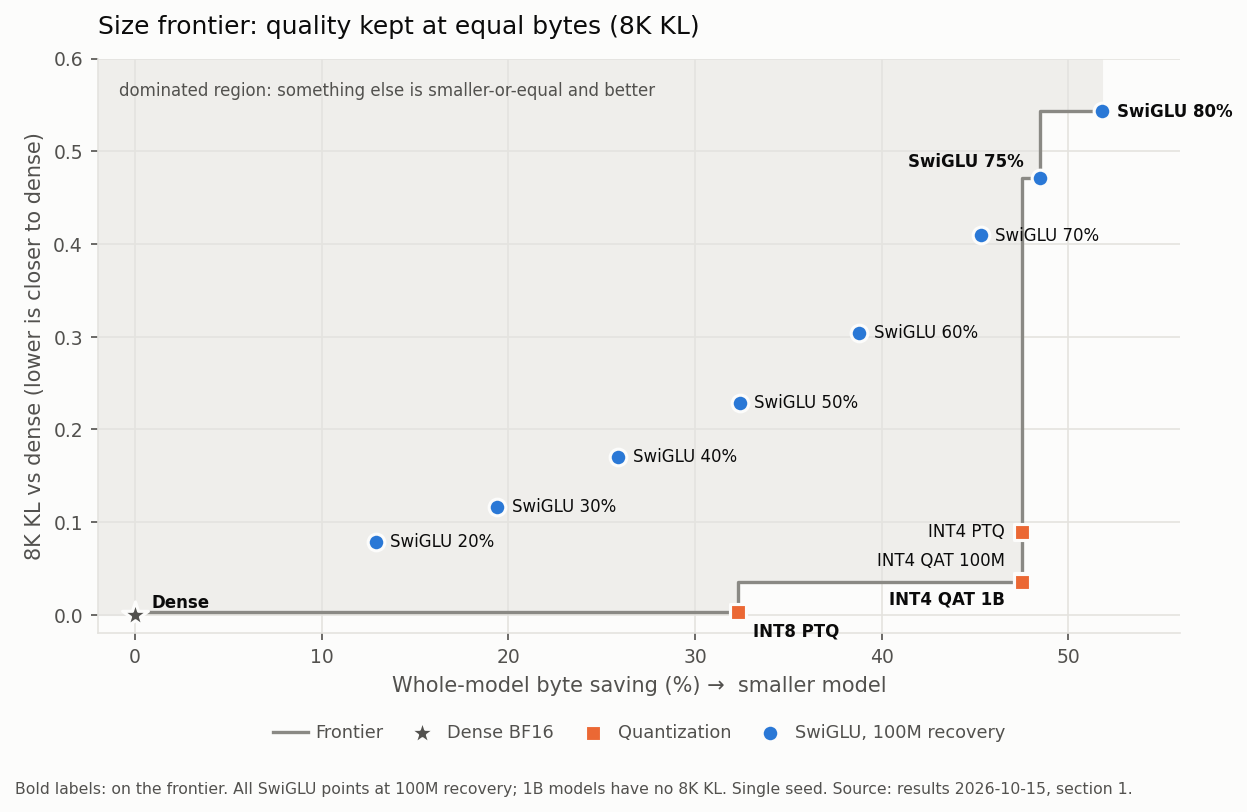

In [6]:
plot_frontier(
    'byte_saving',
    'kl_8k',
    True,
    'Size frontier: quality kept at equal bytes (8K KL)',
    'Whole-model byte saving (%) →  smaller model',
    '8K KL vs dense (lower is closer to dense)',
    'Bold labels: on the frontier. All SwiGLU points at 100M recovery; 1B models have no 8K KL. Single seed. Source: results 2026-10-15, section 1.',
    {
        **{f'SwiGLU {target}%': (7, 0) for target in (20, 30, 40, 50, 60, 70, 80)},
        'SwiGLU 75%': (-8, 8),
        'Dense': (8, 6),
        'INT8 PTQ': (7, -9),
        'INT4 PTQ': (-8, 0),
        'INT4 QAT 100M': (-8, 10),
        'INT4 QAT 1B': (-8, -8),
    },
    (-2, 56),
    (-0.02, 0.60),
    'frontier-size-kl.png',
)

size frontier, test perplexity with 1B recovery

frontier-size-ppl.png frontier: ['Dense', 'INT8 PTQ', 'INT4 QAT 100M', 'SwiGLU 75%', 'SwiGLU 80%']


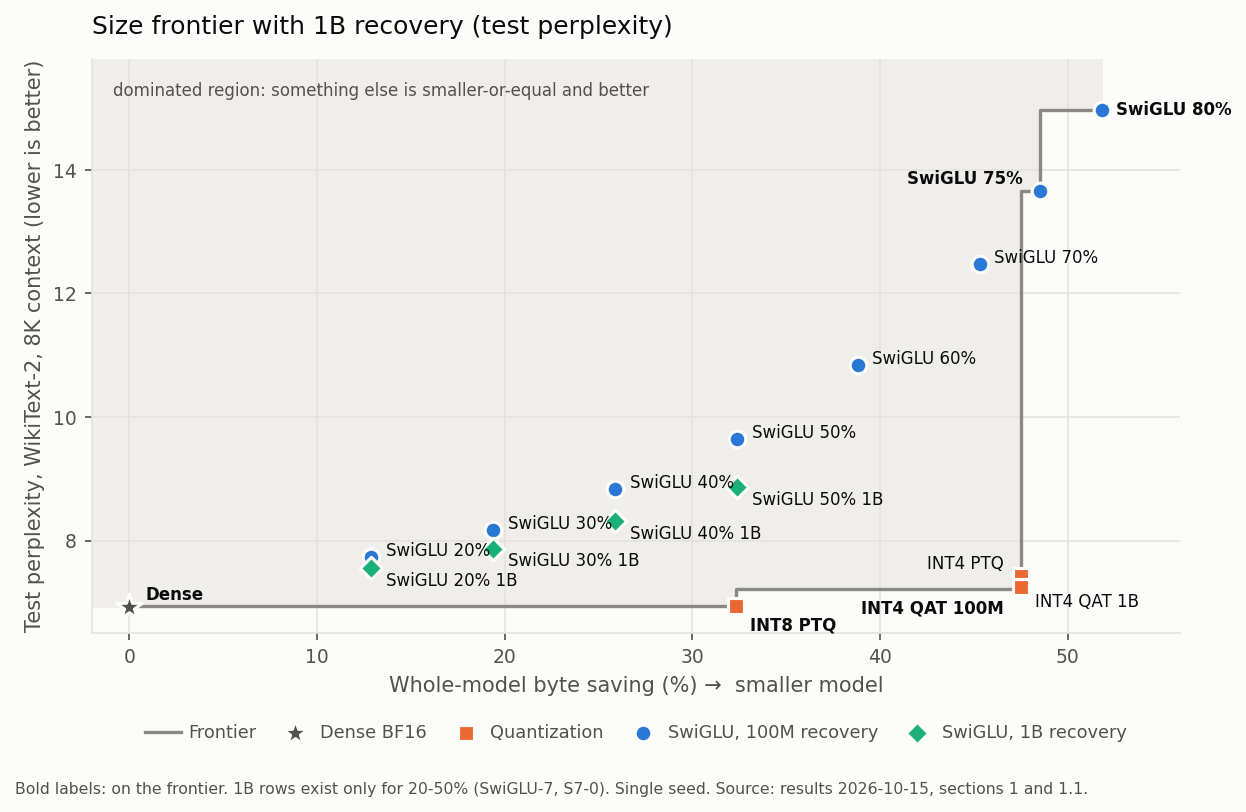

In [7]:
plot_frontier(
    'byte_saving',
    'test_ppl_8k',
    True,
    'Size frontier with 1B recovery (test perplexity)',
    'Whole-model byte saving (%) →  smaller model',
    'Test perplexity, WikiText-2, 8K context (lower is better)',
    'Bold labels: on the frontier. 1B rows exist only for 20-50% (SwiGLU-7, S7-0). Single seed. Source: results 2026-10-15, sections 1 and 1.1.',
    {
        **{f'SwiGLU {target}%': (7, 3) for target in (20, 30, 40, 50, 60, 70)},
        'SwiGLU 75%': (-8, 6),
        'SwiGLU 80%': (7, 0),
        **{f'SwiGLU {target}% 1B': (7, -6) for target in (20, 30, 40, 50)},
        'Dense': (8, 6),
        'INT8 PTQ': (7, -9),
        'INT4 PTQ': (-8, 6),
        'INT4 QAT 100M': (-8, -9),
        'INT4 QAT 1B': (7, -7),
    },
    (-2, 56),
    (6.5, 15.8),
    'frontier-size-ppl.png',
)

speed frontier, time to first token

frontier-ttft-kl.png frontier: ['Dense', 'SwiGLU 20%', 'SwiGLU 30%', 'SwiGLU 40%', 'SwiGLU 50%', 'SwiGLU 70%', 'SwiGLU 75%', 'SwiGLU 80%']


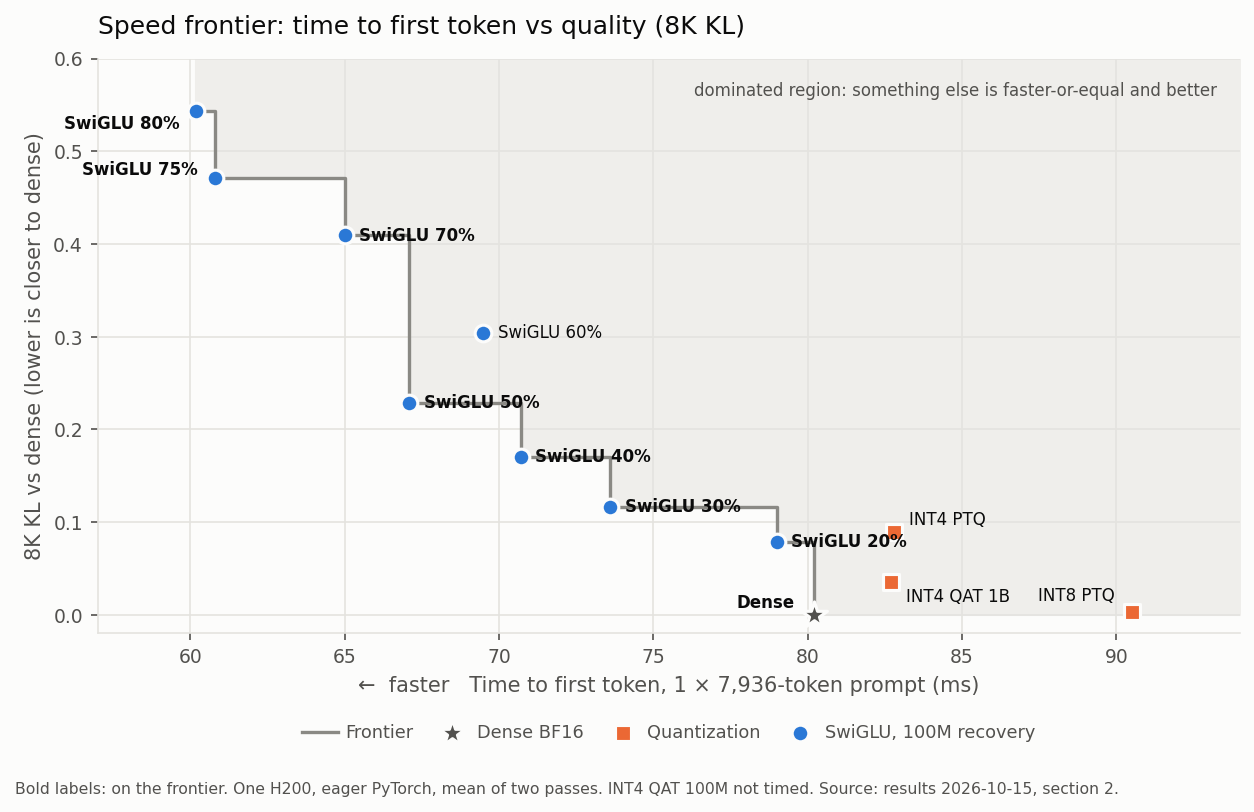

In [8]:
plot_frontier(
    'ttft_ms',
    'kl_8k',
    False,
    'Speed frontier: time to first token vs quality (8K KL)',
    '←  faster   Time to first token, 1 × 7,936-token prompt (ms)',
    '8K KL vs dense (lower is closer to dense)',
    'Bold labels: on the frontier. One H200, eager PyTorch, mean of two passes. INT4 QAT 100M not timed. Source: results 2026-10-15, section 2.',
    {
        **{f'SwiGLU {target}%': (7, 0) for target in (20, 30, 40, 50, 60, 70)},
        'SwiGLU 75%': (-8, 4),
        'SwiGLU 80%': (-8, -6),
        'Dense': (-9, 6),
        'INT8 PTQ': (-8, 8),
        'INT4 PTQ': (7, 6),
        'INT4 QAT 1B': (7, -7),
    },
    (57, 94),
    (-0.02, 0.60),
    'frontier-ttft-kl.png',
)